In [1]:
%pip install -q simplemma vaderSentiment wordcloud joblib

In [2]:
import os, re, ast, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

POS_C, NEG_C, GREY_C, BASE_C = "#2563eb", "#ea580c", "#9ca3af", "#2563eb"
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.labelsize": 10, "font.size": 10,
})
pd.set_option("display.max_colwidth", 120)

if not os.path.exists("reviews_data.csv"):
    try:
        from google.colab import files
        print("Please upload reviews_data.csv")
        files.upload()
    except ImportError:
        raise FileNotFoundError("Put reviews_data.csv in the same folder as this notebook.")
print("Data file found:", os.path.exists("reviews_data.csv"))

Data file found: True


---
# Part 1 – Exploratory Data Analysis (EDA)


In [3]:
raw = pd.read_csv("reviews_data.csv")
raw_str = pd.read_csv("reviews_data.csv", dtype=str, keep_default_na=False)

print("Shape:", raw.shape)
print("\nColumn types (pandas defaults):")
print(raw.dtypes)
print("\nColumn types (as stored):")
print(raw_str.dtypes)
raw.head()

Shape: (850, 6)

Column types (pandas defaults):
name            object
location        object
Date            object
Rating         float64
Review          object
Image_Links     object
dtype: object

Column types (as stored):
name           object
location       object
Date           object
Rating         object
Review         object
Image_Links    object
dtype: object


,name,location,Date,Rating,Review,Image_Links
0,Helen,"Wichita Falls, TX","Reviewed Sept. 13, 2023",5.0,Amber and LaDonna at the Starbucks on Southwest Parkway are always so warm and welcoming. There is always a smile in...,['No Images']
1,Courtney,"Apopka, FL","Reviewed July 16, 2023",5.0,"** at the Starbucks by the fire station on 436 in Altamonte Springs, FL made my day and finally helped me figure out...",['No Images']
2,Daynelle,"Cranberry Twp, PA","Reviewed July 5, 2023",5.0,I just wanted to go out of my way to recognize a Starbucks employee Billy at the Franklin Park location! I was runni...,['https://media.consumeraffairs.com/files/cache/reviews/starbucks_804950_thumbnail.jpg']
3,Taylor,"Seattle, WA","Reviewed May 26, 2023",5.0,"Me and my friend were at Starbucks and my card didn’t work. Thankful the worker there, paid for our drinks. And was ...",['No Images']
4,Tenessa,"Gresham, OR","Reviewed Jan. 22, 2023",5.0,I’m on this kick of drinking 5 cups of warm water. I work for Instacart right now and every location of Starbucks I ...,"['https://media.consumeraffairs.com/files/cache/reviews/starbucks_793785_thumbnail.jpeg', 'https://media.consumeraff..."


In [4]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 850 entries, 0 to 849
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   name         850 non-null    object 
 1   location     850 non-null    object 
 2   Date         850 non-null    object 
 3   Rating       705 non-null    float64
 4   Review       850 non-null    object 
 5   Image_Links  850 non-null    object 
dtypes: float64(1), object(5)
memory usage: 40.0+ KB


### 1.2 Missing values, duplicates, strange / placeholder values (every column)

In [5]:
print("Missing values with pandas defaults (NaN):")
print(raw.isna().sum())

placeholder_checks = {
    "Rating == 'N/A'":                    (raw_str.Rating.str.strip() == "N/A"),
    "Review == 'No Review Text'":         (raw_str.Review.str.strip().str.lower() == "no review text"),
    "Image_Links == ['No Images']":       (raw_str.Image_Links == "['No Images']"),
    "location has no 'City, ST' comma":   (~raw_str.location.str.contains(",")),
    "location state == 'Other'":          (raw_str.location.str.endswith(", Other")),
    "name / location has extra spaces":   ((raw_str.name != raw_str.name.str.strip()) | (raw_str.location != raw_str.location.str.strip())),
    "name contains digits or punctuation": (~raw_str.name.str.strip().str.match(r"^[A-Za-z][A-Za-z .'-]*$")),
    "Review contains '**' (masked text)": raw_str.Review.str.contains(r"\*\*"),
    "Review has non-ASCII characters (’ “ ” é ...)": raw_str.Review.str.contains(r"[^\x00-\x7f]"),
    "Review shorter than 40 characters":  (raw_str.Review.str.len() < 40),
}
ph = pd.Series({k: int(v.sum()) for k, v in placeholder_checks.items()}, name="rows affected")
display(ph.to_frame())

print("\nDuplicates:")
placeholder_review = raw_str.Review.str.strip().str.lower() == "no review text"
dup_exact = raw_str.duplicated().sum()
dup_row_key = raw_str.duplicated(["name", "location", "Date", "Review"]).sum()
dup_text = raw_str[~placeholder_review].duplicated("Review").sum()
print(" exact duplicate rows                          :", dup_exact)
print(" duplicate (name, location, Date, Review)       :", dup_row_key)
print(" duplicate review text (excluding placeholders) :", dup_text)
raw_str[~placeholder_review & raw_str.duplicated("Review", keep=False)].sort_values("Review")[["name", "Date", "Rating", "Review"]].head(6)

Missing values with pandas defaults (NaN):
name             0
location         0
Date             0
Rating         145
Review           0
Image_Links      0
dtype: int64


,rows affected
Rating == 'N/A',145
Review == 'No Review Text',37
Image_Links == ['No Images'],804
"location has no 'City, ST' comma",2
location state == 'Other',41
name / location has extra spaces,10
name contains digits or punctuation,2
Review contains '**' (masked text),61
Review has non-ASCII characters (’ “ ” é ...),101
Review shorter than 40 characters,37



Duplicates:
 exact duplicate rows                          : 1
 duplicate (name, location, Date, Review)       : 1
 duplicate review text (excluding placeholders) : 0


,name,Date,Rating,Review


### 1.3 Are the column types right? (is `Date` a real date?)

In [6]:
print("Date dtype:", raw.Date.dtype, "-> it is text, not datetime")
print("Examples:", raw.Date.head(3).tolist())
print("All values start with 'Reviewed':", raw.Date.str.startswith("Reviewed").all())
print("Rows using the abbreviation 'Sept.' (not parseable by default):", raw.Date.str.contains("Sept.", regex=False).sum())

naive = pd.to_datetime(raw.Date, errors="coerce")
print("Naive pd.to_datetime -> unparseable rows:", naive.isna().sum(), "of", len(raw))

print("\nRating dtype:", raw.Rating.dtype, "(float, because of the 'N/A' text; ratings should be integers 1-5)")
print("Image_Links dtype:", raw.Image_Links.dtype, "-> a Python list stored as a string, e.g.", raw.Image_Links.iloc[4][:80], "...")

Date dtype: object -> it is text, not datetime
Examples: ['Reviewed Sept. 13, 2023', 'Reviewed July 16, 2023', 'Reviewed July 5, 2023']
All values start with 'Reviewed': True
Rows using the abbreviation 'Sept.' (not parseable by default): 89
Naive pd.to_datetime -> unparseable rows: 850 of 850

Rating dtype: float64 (float, because of the 'N/A' text; ratings should be integers 1-5)
Image_Links dtype: object -> a Python list stored as a string, e.g. ['https://media.consumeraffairs.com/files/cache/reviews/starbucks_793785_thumbna ...


### 1.4 Plots: rating counts, review lengths, reviews over time

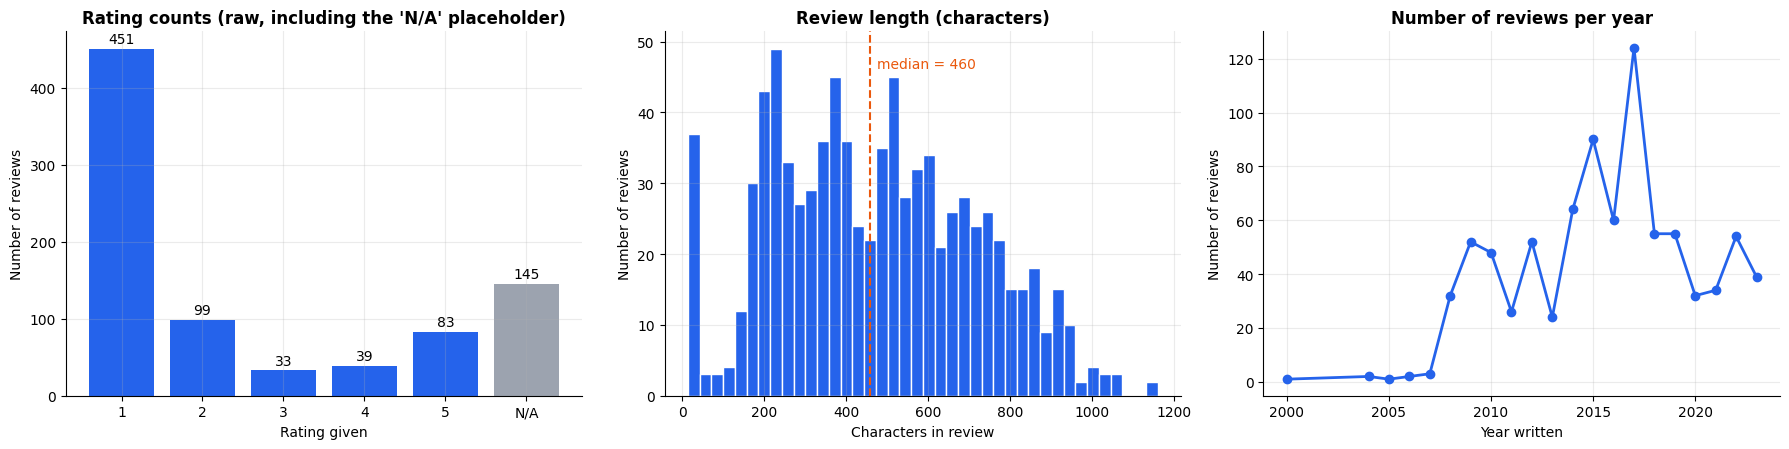

Review length summary:
count     850.0
mean      471.1
std       243.5
min        14.0
25%       272.0
50%       459.5
75%       655.2
max      1161.0
Name: Review, dtype: float64

Date range: 2000-07-19 to 2023-09-14


In [7]:
tmp_date = pd.to_datetime(raw_str.Date.str.replace("Reviewed ", "", regex=False)
                          .str.replace("Sept.", "Sep.", regex=False).str.replace(".", "", regex=False), format="mixed")
review_len = raw_str.Review.str.len()

fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))

order = ["1", "2", "3", "4", "5", "N/A"]
counts = raw_str.Rating.value_counts().reindex(order)
bars = ax[0].bar(order, counts.values, color=[BASE_C] * 5 + [GREY_C])
ax[0].bar_label(bars, padding=2)
ax[0].set_title("Rating counts (raw, including the 'N/A' placeholder)")
ax[0].set_xlabel("Rating given"); ax[0].set_ylabel("Number of reviews")

ax[1].hist(review_len, bins=40, color=BASE_C, edgecolor="white")
ax[1].axvline(review_len.median(), color=NEG_C, ls="--", lw=1.5)
ax[1].text(review_len.median() + 15, ax[1].get_ylim()[1] * .9, f"median = {review_len.median():.0f}", color=NEG_C)
ax[1].set_title("Review length (characters)")
ax[1].set_xlabel("Characters in review"); ax[1].set_ylabel("Number of reviews")

per_year = tmp_date.dt.year.value_counts().sort_index()
ax[2].plot(per_year.index, per_year.values, marker="o", color=BASE_C, lw=2)
ax[2].set_title("Number of reviews per year")
ax[2].set_xlabel("Year written"); ax[2].set_ylabel("Number of reviews")
plt.tight_layout(); plt.show()

print("Review length summary:"); print(review_len.describe().round(1))
print("\nDate range:", tmp_date.min().date(), "to", tmp_date.max().date())

### 1.5 Problem list – every problem found, with the number of rows it affects

In [8]:
n = len(raw_str)
n_na_rating   = int(placeholder_checks["Rating == 'N/A'"].sum())
n_noreview    = int(placeholder_checks["Review == 'No Review Text'"].sum())
n_noimg       = int(placeholder_checks["Image_Links == ['No Images']"].sum())
n_sept        = int(raw_str.Date.str.contains("Sept.", regex=False).sum())
n_masked      = int(placeholder_checks["Review contains '**' (masked text)"].sum())
n_nonascii    = int(placeholder_checks["Review has non-ASCII characters (’ “ ” é ...)"].sum())
n_ws          = int(placeholder_checks["name / location has extra spaces"].sum())
n_badname     = int(placeholder_checks["name contains digits or punctuation"].sum())
n_noloc       = int(placeholder_checks["location has no 'City, ST' comma"].sum())
n_other       = int(placeholder_checks["location state == 'Other'"].sum())
n_short       = int(placeholder_checks["Review shorter than 40 characters"].sum())

problems = pd.DataFrame([
    ("Rating", "Placeholder text 'N/A' instead of a rating (pandas hides it as NaN)", n_na_rating),
    ("Rating", "Wrong type: float / text instead of integer 1-5", n),
    ("Review", "Placeholder text 'No Review Text' (no real review)", n_noreview),
    ("Row", "Exact duplicate row (it sits among the 'N/A' rating rows)", int(dup_exact)),
    ("Review", "Masked words '**' inside the text (anonymised names)", n_masked),
    ("Review", "Non-ASCII characters (curly quotes etc.) that break simple regexes", n_nonascii),
    ("Review", "Very short reviews (< 40 characters), mostly the placeholder", n_short),
    ("Date", "Stored as text with a 'Reviewed ' prefix, not a datetime", n),
    ("Date", "Month abbreviation 'Sept.' is not understood by the date parser", n_sept),
    ("name", "Leading/trailing spaces, inconsistent capitalisation", n_ws),
    ("name", "Names with digits or stray punctuation (e.g. '84euni', 'Nan-Yen,')", n_badname),
    ("location", "Two fields in one column ('City, ST'), not split", n),
    ("location", "State recorded as 'Other' (non-US) and country-only values without a comma", n_other + n_noloc),
    ("Image_Links", "Python list stored as a string; 'No Images' used as a placeholder", n),
    ("Image_Links", "'No Images' placeholder rows", n_noimg),
    ("Dataset", "Class imbalance: 1-star reviews dominate (see rating plot)", int((raw_str.Rating == "1").sum())),
    ("Dataset", "Reviews span 2000-2023 and are very unevenly spread across years", n),
], columns=["column", "problem", "rows affected"])
problems.index = problems.index + 1
display(problems)

,column,problem,rows affected
1,Rating,Placeholder text 'N/A' instead of a rating (pandas hides it as NaN),145
2,Rating,Wrong type: float / text instead of integer 1-5,850
3,Review,Placeholder text 'No Review Text' (no real review),37
4,Row,Exact duplicate row (it sits among the 'N/A' rating rows),1
5,Review,Masked words '**' inside the text (anonymised names),61
6,Review,Non-ASCII characters (curly quotes etc.) that break simple regexes,101
7,Review,"Very short reviews (< 40 characters), mostly the placeholder",37
8,Date,"Stored as text with a 'Reviewed ' prefix, not a datetime",850
9,Date,Month abbreviation 'Sept.' is not understood by the date parser,89
10,name,"Leading/trailing spaces, inconsistent capitalisation",10


---
# Part 2 – Cleaning and Pre-processing
### 2.1 Fix every problem from Part 1


In [9]:
df = raw_str.copy()
log_rows = []

def log(step, why):
    log_rows.append((step, len(df)))
    print(f"[{step}] rows left: {len(df):>4}  |  why: {why}")

log("0. start", "raw file, 850 rows.")

for c in df.columns:
    df[c] = df[c].str.strip()
log("1. strip spaces", "stray spaces create fake differences between identical values and break matching.")

df["Rating"] = pd.to_numeric(df["Rating"].replace("N/A", np.nan), errors="coerce")
n_before = len(df)
df = df.dropna(subset=["Rating"]).copy()
df["Rating"] = df["Rating"].astype(int)
assert df["Rating"].between(1, 5).all()
log("2. drop Rating=N/A", f"the rating is the only source of our label; {n_before - len(df)} rows without it cannot be used for supervised learning (guessing would inject noise).")

n_before = len(df)
df = df[(df["Review"].str.lower() != "no review text") & (df["Review"].str.len() > 0)].copy()
log("3. drop 'No Review Text'", f"{n_before - len(df)} rows have a rating but no text, so there is nothing for a text model to learn from.")

n_dup_rows = int(df.duplicated(["name", "location", "Date", "Review"]).sum())
df = df.drop_duplicates(subset=["name", "location", "Date", "Review"])
log("4a. drop exact duplicates", f"{n_dup_rows} left to remove: the one exact duplicate found in Part 1 was an 'N/A' row, already gone in step 2. Duplicates would leak between train and test.")
n_dup_txt = int(df.duplicated("Review").sum())
df = df.drop_duplicates(subset="Review", keep="first").copy()
log("4b. drop duplicate texts", f"{n_dup_txt} repeated review texts left; kept the first of each so identical text cannot sit in both train and test.")

df["Date"] = pd.to_datetime(
    df["Date"].str.replace(r"^Reviewed\s+", "", regex=True)
              .str.replace("Sept.", "Sep.", regex=False).str.replace(".", "", regex=False),
    format="mixed")
assert df["Date"].notna().all()
df["year"], df["month"] = df["Date"].dt.year, df["Date"].dt.month
log("5. Date -> datetime", "a real datetime lets us sort, group by year, and plot trends. Prefix and 'Sept.' removed first.")

df["name"] = (df["name"].str.replace(r"[^A-Za-z .'-]", "", regex=True).str.strip(" .-'")
                        .replace("", np.nan))
df["name"] = df["name"].where(~(df["name"].str.isupper() | df["name"].str.islower()), df["name"].str.title())
log("6. tidy name", "removed digits/punctuation and unified capitalisation. (Names are not used by the model; they are personal data and kept only for reference.)")

parts = df["location"].str.split(",", n=1, expand=True)
df["city"] = parts[0].where(parts[1].notna())
df["region"] = parts[1].fillna(parts[0]).str.strip().replace({"Other": "Non-US / Other"})
df = df.drop(columns="location")
log("7. split location", "one column held two facts. City is NaN for country-only values (Canada, UK); 'Other' renamed to a clear label.")

def count_images(s):
    lst = ast.literal_eval(s)
    return 0 if lst == ["No Images"] else len(lst)
df["n_images"] = df["Image_Links"].apply(count_images)
df["has_image"] = df["n_images"] > 0
df = df.drop(columns="Image_Links")
log("8. parse Image_Links", "turned a string-list with a placeholder into a clean number + flag; the URLs themselves are not useful for text sentiment.")

df["Review"] = (df["Review"].str.replace("\u2019", "'", regex=False).str.replace("\u2018", "'", regex=False)
                .str.replace("\u201c", '"', regex=False).str.replace("\u201d", '"', regex=False)
                .str.replace(r"\s+", " ", regex=True).str.strip())
log("9. normalise quotes/spaces", "curly quotes and line breaks removed so regexes behave; the wording itself is untouched.")
df = df.reset_index(drop=True)
print("\nDtypes after cleaning:"); print(df.dtypes)

[0. start] rows left:  850  |  why: raw file, 850 rows.
[1. strip spaces] rows left:  850  |  why: stray spaces create fake differences between identical values and break matching.
[2. drop Rating=N/A] rows left:  705  |  why: the rating is the only source of our label; 145 rows without it cannot be used for supervised learning (guessing would inject noise).
[3. drop 'No Review Text'] rows left:  703  |  why: 2 rows have a rating but no text, so there is nothing for a text model to learn from.
[4a. drop exact duplicates] rows left:  703  |  why: 0 left to remove: the one exact duplicate found in Part 1 was an 'N/A' row, already gone in step 2. Duplicates would leak between train and test.
[4b. drop duplicate texts] rows left:  703  |  why: 0 repeated review texts left; kept the first of each so identical text cannot sit in both train and test.
[5. Date -> datetime] rows left:  703  |  why: a real datetime lets us sort, group by year, and plot trends. Prefix and 'Sept.' removed first.
[

### 2.2 Text pre-processing: lowercase, remove noise, remove filler words, lemmatise



### 2.3 Negation words – should they be removed? **No. We keep them.**


In [10]:
%%writefile text_utils.py
"""Shared text cleaning for the sentiment project (used by the notebook and the Streamlit app)."""
import re
import simplemma

_STOP = """
i me my myself we our ours ourselves you your yours yourself yourselves he him his himself she her hers herself
it its itself they them their theirs themselves what which who whom this that these those am is are was were be
been being have has had having do does did doing a an the and but if or because as until while of at by for with
about between into through during before after above below to from up down in out on off over under again further
then once here there when where why how all any both each few more most other some such own same so than too very
s t can will just should now would could also get got one even really
"""
NEGATIONS = {"not", "no", "nor", "never", "none", "nothing", "nobody", "nowhere", "neither", "cannot", "without", "hardly"}
STOP_WORDS = set(_STOP.split()) - NEGATIONS

_URL = re.compile(r"(https?://\S+|www\.\S+)")
_HTML = re.compile(r"<[^>]+>")
_CONTRACTIONS = [
    (r"\bwon't\b", "will not"), (r"\bcan't\b", "can not"), (r"\bcannot\b", "can not"), (r"\bain't\b", "is not"),
    (r"n't\b", " not"), (r"'re\b", " are"), (r"'ll\b", " will"), (r"'ve\b", " have"), (r"'m\b", " am"), (r"'d\b", " would"),
]

_FUSE = {"not", "no", "never", "without", "hardly", "neither", "nor"}

def _fuse_negations(tokens):
    out, i = [], 0
    while i < len(tokens):
        w = tokens[i]
        if w in _FUSE and i + 1 < len(tokens) and tokens[i + 1] not in NEGATIONS:
            out.append(w + "_" + tokens[i + 1])
            i += 2
        else:
            out.append(w)
            i += 1
    return out

def clean_text(text, lemmatize=True):
    """lowercase -> remove links/html/symbols -> expand contractions -> tokenise -> drop stop-words (keep negations) -> lemmatise."""
    if not isinstance(text, str):
        return ""
    t = text.lower().replace("\u2019", "'").replace("\u2018", "'")
    t = _URL.sub(" ", t)
    t = _HTML.sub(" ", t)
    t = t.replace("*", " ")
    for pat, rep in _CONTRACTIONS:
        t = re.sub(pat, rep, t)
    t = re.sub(r"'s\b", " ", t)
    t = re.sub(r"[^a-z\s]", " ", t)
    tokens = t.split()
    tokens = [w for w in tokens if (w not in STOP_WORDS and len(w) > 1) or w in NEGATIONS]
    if lemmatize:
        tokens = [simplemma.lemmatize(w, lang="en") for w in tokens]
        tokens = [w for w in tokens if w not in STOP_WORDS]
    tokens = _fuse_negations(tokens)
    return " ".join(tokens)

Writing text_utils.py


In [11]:
import importlib, text_utils
importlib.reload(text_utils)
from text_utils import clean_text, STOP_WORDS, NEGATIONS

print("Stop-words removed:", len(STOP_WORDS), "| negations kept:", sorted(NEGATIONS))
print("Check  -> 'not' removed? ", "not" in STOP_WORDS, "| 'never' removed?", "never" in STOP_WORDS)

df["clean_text"] = df["Review"].apply(clean_text)
df["n_words_raw"] = df["Review"].str.split().str.len()
df["n_words_clean"] = df["clean_text"].str.split().str.len()

empty = df["clean_text"].str.strip() == ""
df = df[~empty].reset_index(drop=True)
log("10. drop empty after cleaning", f"{int(empty.sum())} reviews had no usable words left.")

Stop-words removed: 129 | negations kept: ['cannot', 'hardly', 'neither', 'never', 'no', 'nobody', 'none', 'nor', 'not', 'nothing', 'nowhere', 'without']
Check  -> 'not' removed?  False | 'never' removed? False
[10. drop empty after cleaning] rows left:  703  |  why: 0 reviews had no usable words left.


### 2.4 One review before and after cleaning

In [12]:
sample = df[df.Review.str.contains(r"n't| not |never", case=False) & (df.n_words_raw.between(25, 45))].iloc[0]
print("BEFORE:\n", sample.Review)
print("\nAFTER :\n", sample.clean_text)
print(f"\nWords: {sample.n_words_raw} -> {sample.n_words_clean}")

print("\nNegation test:")
for s in ["The coffee is good", "The coffee is not good", "They never got my order right", "I can't complain, it didn't disappoint"]:
    print(f"  {s!r:48} -> {clean_text(s)!r}")

BEFORE:
 I spend about $30/day, is it asking too much to have a lid that does not fall off? I have contacted Starbucks customer service for months being told they are addressing the issue but nothing changes.

AFTER :
 spend day ask much lid not_fall contact starbucks customer service month tell address issue nothing change

Words: 36 -> 16

Negation test:
  'The coffee is good'                             -> 'coffee good'
  'The coffee is not good'                         -> 'coffee not_good'
  'They never got my order right'                  -> 'never_order right'
  "I can't complain, it didn't disappoint"         -> 'not_complain not_disappoint'


---
# Part 3 – Sentiment Labels
### 3.1 / 3.2 Rating → sentiment and what to do with the middle rating


In [13]:
def rating_to_sentiment(r):
    if r <= 2: return "Negative"
    if r >= 4: return "Positive"
    return "Neutral"

df["sentiment"] = df["Rating"].apply(rating_to_sentiment)
print("Before dropping neutral:"); print(df.sentiment.value_counts())

df = df[df.sentiment != "Neutral"].reset_index(drop=True)
df["label"] = (df.sentiment == "Positive").astype(int)
log("11. drop 3-star reviews", "ambiguous middle rating removed (see table above).")

Before dropping neutral:
sentiment
Negative    548
Positive    122
Neutral      33
Name: count, dtype: int64
[11. drop 3-star reviews] rows left:  670  |  why: ambiguous middle rating removed (see table above).


### 3.3 How many reviews per label? Is the data balanced?

,reviews,percent
sentiment,,
Negative,548,81.8
Positive,122,18.2


Imbalance ratio  Negative : Positive = 4.5 : 1
A dumb model that always says 'Negative' would already score 81.8% accuracy.


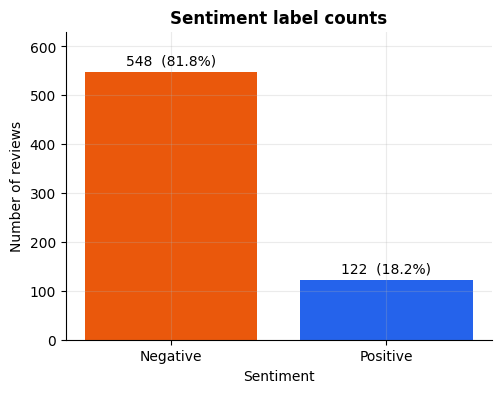

In [14]:
counts = df.sentiment.value_counts()
pct = (counts / counts.sum() * 100).round(1)
display(pd.DataFrame({"reviews": counts, "percent": pct}))
ratio = counts["Negative"] / counts["Positive"]
print(f"Imbalance ratio  Negative : Positive = {ratio:.1f} : 1")
print(f"A dumb model that always says 'Negative' would already score {counts.max() / counts.sum():.1%} accuracy.")

fig, ax = plt.subplots(figsize=(5.5, 4))
b = ax.bar(counts.index, counts.values, color=[NEG_C if i == "Negative" else POS_C for i in counts.index])
ax.bar_label(b, labels=[f"{v}  ({p}%)" for v, p in zip(counts.values, pct.values)], padding=3)
ax.set_title("Sentiment label counts"); ax.set_ylabel("Number of reviews"); ax.set_xlabel("Sentiment")
ax.set_ylim(0, counts.max() * 1.15); plt.show()

In [15]:
# save the cleaned dataset (deliverable)
out_cols = ["name", "city", "region", "Date", "year", "Rating", "sentiment", "label", "Review", "clean_text", "n_words_raw", "n_words_clean", "n_images", "has_image"]
df[out_cols].to_csv("cleaned_reviews.csv", index=False)
print("Saved cleaned_reviews.csv ->", df.shape[0], "rows,", len(out_cols), "columns")
print("\nRow count after every step:")
display(pd.DataFrame(log_rows, columns=["step", "rows left"]))

Saved cleaned_reviews.csv -> 670 rows, 14 columns

Row count after every step:


,step,rows left
0,0. start,850
1,1. strip spaces,850
2,2. drop Rating=N/A,705
3,3. drop 'No Review Text',703
4,4a. drop exact duplicates,703
5,4b. drop duplicate texts,703
6,5. Date -> datetime,703
7,6. tidy name,703
8,7. split location,703
9,8. parse Image_Links,703


---
# Part 4 – Visualisation

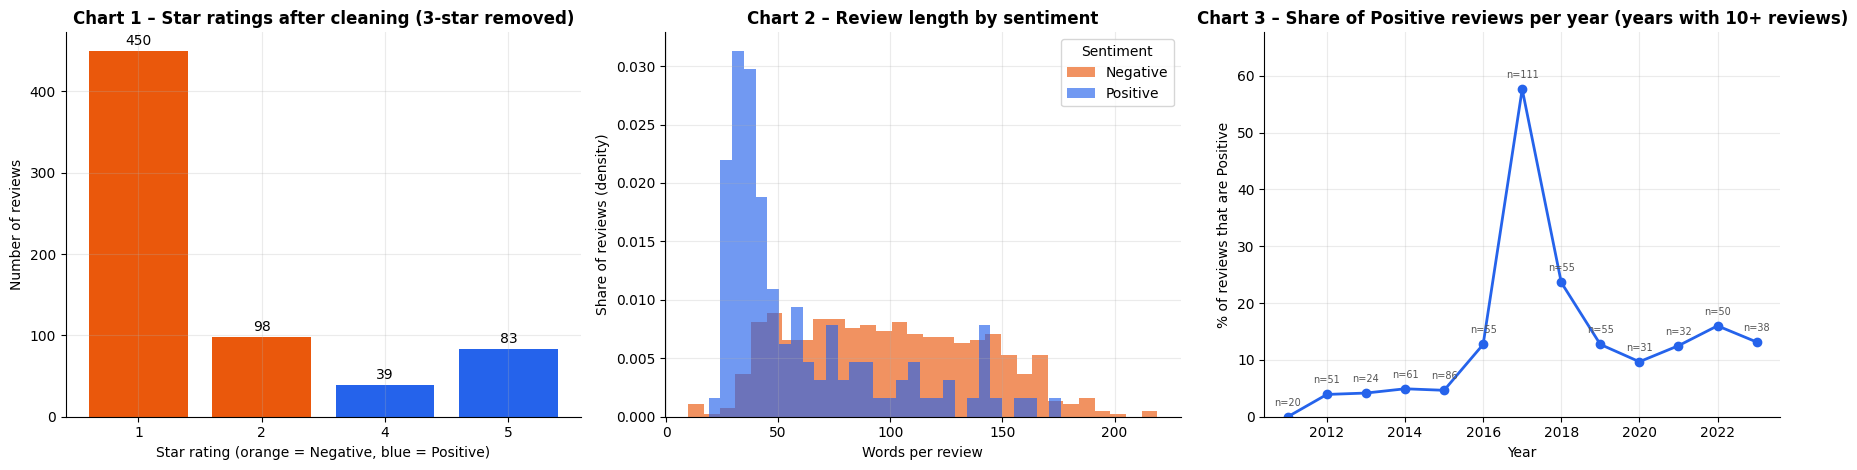

In [16]:
from collections import Counter

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))

rc = df.Rating.value_counts().sort_index()
b = ax[0].bar(rc.index.astype(str), rc.values, color=[NEG_C, NEG_C, POS_C, POS_C])
ax[0].bar_label(b, padding=2)
ax[0].set_title("Chart 1 – Star ratings after cleaning (3-star removed)")
ax[0].set_xlabel("Star rating (orange = Negative, blue = Positive)"); ax[0].set_ylabel("Number of reviews")

for s, c in [("Negative", NEG_C), ("Positive", POS_C)]:
    ax[1].hist(df[df.sentiment == s].n_words_raw, bins=30, alpha=.65, color=c, label=s, density=True)
ax[1].set_title("Chart 2 – Review length by sentiment")
ax[1].set_xlabel("Words per review"); ax[1].set_ylabel("Share of reviews (density)"); ax[1].legend(title="Sentiment")

yr = df.groupby("year").agg(n=("label", "size"), pos=("label", "mean"))
yr = yr[yr.n >= 10]
ax[2].plot(yr.index, yr.pos * 100, marker="o", color=POS_C, lw=2)
for x, y, n_ in zip(yr.index, yr.pos * 100, yr.n):
    ax[2].annotate(f"n={n_}", (x, y), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=7, color="#555")
ax[2].set_title("Chart 3 – Share of Positive reviews per year (years with 10+ reviews)")
ax[2].set_xlabel("Year"); ax[2].set_ylabel("% of reviews that are Positive"); ax[2].set_ylim(0, max(60, yr.pos.max() * 100 + 10))
plt.tight_layout(); plt.show()

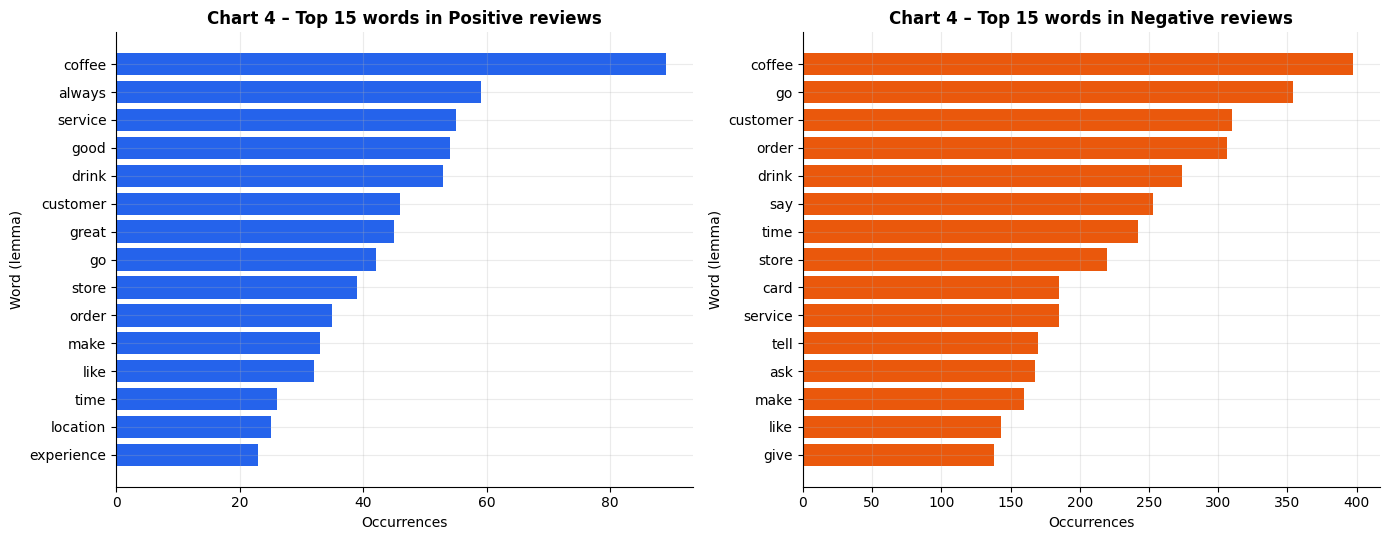

In [17]:
SHOW_DROP = {"starbucks"}
def top_words(texts, k=15):
    c = Counter(w for t in texts for w in t.split() if w not in SHOW_DROP)
    return c

pos_counter = top_words(df[df.label == 1].clean_text)
neg_counter = top_words(df[df.label == 0].clean_text)

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for a, counter, col, name in [(ax[0], pos_counter, POS_C, "Positive"), (ax[1], neg_counter, NEG_C, "Negative")]:
    words, vals = zip(*counter.most_common(15)[::-1])
    a.barh(words, vals, color=col)
    a.set_title(f"Chart 4 – Top 15 words in {name} reviews"); a.set_xlabel("Occurrences"); a.set_ylabel("Word (lemma)")
plt.tight_layout(); plt.show()

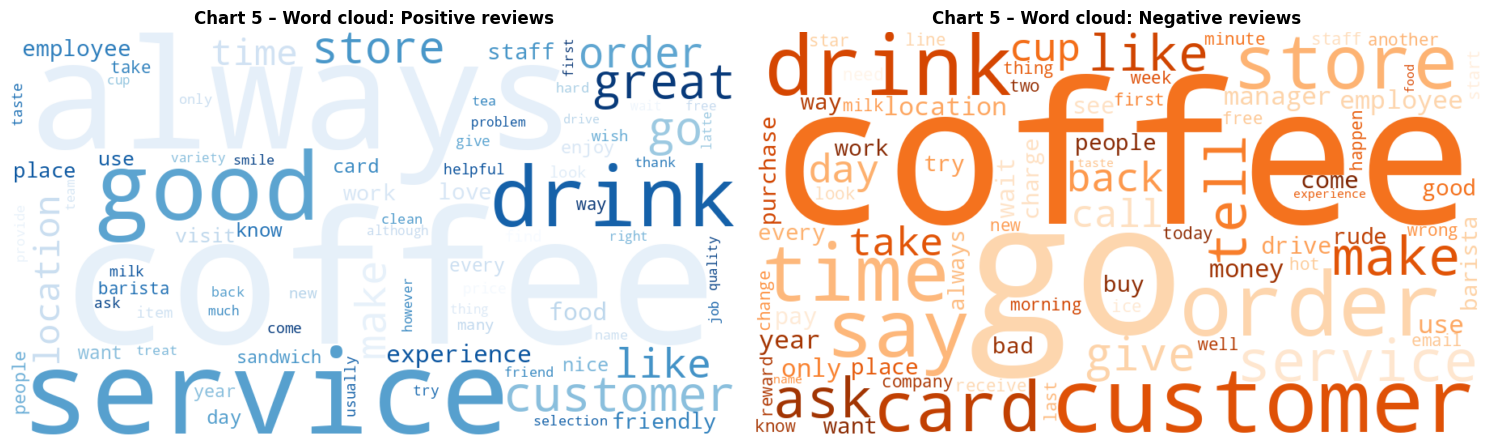

In [18]:
from wordcloud import WordCloud
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
for a, counter, cmap, name in [(ax[0], pos_counter, "Blues", "Positive"), (ax[1], neg_counter, "Oranges", "Negative")]:
    wc = WordCloud(width=900, height=500, background_color="white", colormap=cmap, max_words=80, random_state=RANDOM_STATE)
    a.imshow(wc.generate_from_frequencies(counter), interpolation="bilinear"); a.axis("off")
    a.set_title(f"Chart 5 – Word cloud: {name} reviews", fontweight="bold")
plt.tight_layout(); plt.show()

---
# Part 5 – Build and Test Models
### 5.1 / 5.2 Text → numbers (TF-IDF) and a stratified 80/20 split


In [19]:
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score,
                             confusion_matrix, classification_report)

train_df, test_df = train_test_split(df, test_size=0.20, stratify=df.label, random_state=RANDOM_STATE)
X_train, y_train = train_df.clean_text, train_df.label
X_test,  y_test  = test_df.clean_text,  test_df.label

print(f"Train: {len(train_df)} rows | Test: {len(test_df)} rows")
print("Positive share  -> train: {:.3f} | test: {:.3f} | all: {:.3f}".format(y_train.mean(), y_test.mean(), df.label.mean()))

demo_vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit(X_train)
Xt = demo_vec.transform(X_train)
print(f"\nTF-IDF matrix (train): {Xt.shape[0]} reviews x {Xt.shape[1]} features, {Xt.nnz / (Xt.shape[0] * Xt.shape[1]):.2%} non-zero")
print("Example features:", list(demo_vec.get_feature_names_out()[:8]), "...", [f for f in demo_vec.get_feature_names_out() if f.startswith("not ")][:6])

Train: 536 rows | Test: 134 rows
Positive share  -> train: 0.183 | test: 0.179 | all: 0.182

TF-IDF matrix (train): 536 reviews x 3335 features, 1.17% non-zero
Example features: ['able', 'absolute', 'absolutely', 'accept', 'acceptable', 'access', 'accidentally', 'accommodate'] ... []


### 5.3 Train the models



In [20]:
def make_pipe(clf, ngram=(1, 2)):
    return Pipeline([("tfidf", TfidfVectorizer(ngram_range=ngram, min_df=2, sublinear_tf=True)), ("clf", clf)])

models = {
    "Baseline (always majority)":    make_pipe(DummyClassifier(strategy="most_frequent")),
    "Naive Bayes (Multinomial)":     make_pipe(MultinomialNB(alpha=0.5)),
    "Naive Bayes (Complement)":      make_pipe(ComplementNB(alpha=0.5)),
    "Logistic Regression":           make_pipe(LogisticRegression(max_iter=2000, class_weight="balanced", C=3, random_state=RANDOM_STATE)),
    "Linear SVM":                    make_pipe(LinearSVC(class_weight="balanced", C=0.5, random_state=RANDOM_STATE)),
}
for name, m in models.items():
    m.fit(X_train, y_train)
print("Trained:", list(models))

Trained: ['Baseline (always majority)', 'Naive Bayes (Multinomial)', 'Naive Bayes (Complement)', 'Logistic Regression', 'Linear SVM']


### 5.4 Evaluate: accuracy, precision, recall, F1 and confusion matrix


In [21]:
def evaluate(name, model_or_pred, X, y):
    pred = model_or_pred if isinstance(model_or_pred, (np.ndarray, pd.Series, list)) else model_or_pred.predict(X)
    return {
        "Model": name,
        "Accuracy": accuracy_score(y, pred),
        "Precision (Pos)": precision_score(y, pred, zero_division=0),
        "Recall (Pos)": recall_score(y, pred, zero_division=0),
        "F1 (Pos)": f1_score(y, pred, zero_division=0),
        "Macro F1": f1_score(y, pred, average="macro", zero_division=0),
        "Balanced Acc": balanced_accuracy_score(y, pred),
    }, np.asarray(pred)

rows, preds = [], {}
for name, m in models.items():
    r, p = evaluate(name, m, X_test, y_test)
    rows.append(r); preds[name] = p
results = pd.DataFrame(rows).set_index("Model")
display(results.round(3).style.background_gradient(cmap="Blues", axis=0))

for name in ["Naive Bayes (Complement)", "Logistic Regression", "Linear SVM"]:
    print("=" * 60, "\n", name); print(classification_report(y_test, preds[name], target_names=["Negative", "Positive"], zero_division=0))

,Accuracy,Precision (Pos),Recall (Pos),F1 (Pos),Macro F1,Balanced Acc
Model,,,,,,
Baseline (always majority),0.821000,0.000000,0.000000,0.000000,0.451000,0.500000
Naive Bayes (Multinomial),0.836000,1.000000,0.083000,0.154000,0.531000,0.542000
Naive Bayes (Complement),0.910000,0.929000,0.542000,0.684000,0.816000,0.766000
Logistic Regression,0.925000,0.889000,0.667000,0.762000,0.859000,0.824000
Linear SVM,0.940000,1.000000,0.667000,0.800000,0.882000,0.833000


 Naive Bayes (Complement)
              precision    recall  f1-score   support

    Negative       0.91      0.99      0.95       110
    Positive       0.93      0.54      0.68        24

    accuracy                           0.91       134
   macro avg       0.92      0.77      0.82       134
weighted avg       0.91      0.91      0.90       134

 Logistic Regression
              precision    recall  f1-score   support

    Negative       0.93      0.98      0.96       110
    Positive       0.89      0.67      0.76        24

    accuracy                           0.93       134
   macro avg       0.91      0.82      0.86       134
weighted avg       0.92      0.93      0.92       134

 Linear SVM
              precision    recall  f1-score   support

    Negative       0.93      1.00      0.96       110
    Positive       1.00      0.67      0.80        24

    accuracy                           0.94       134
   macro avg       0.97      0.83      0.88       134
weighted avg   

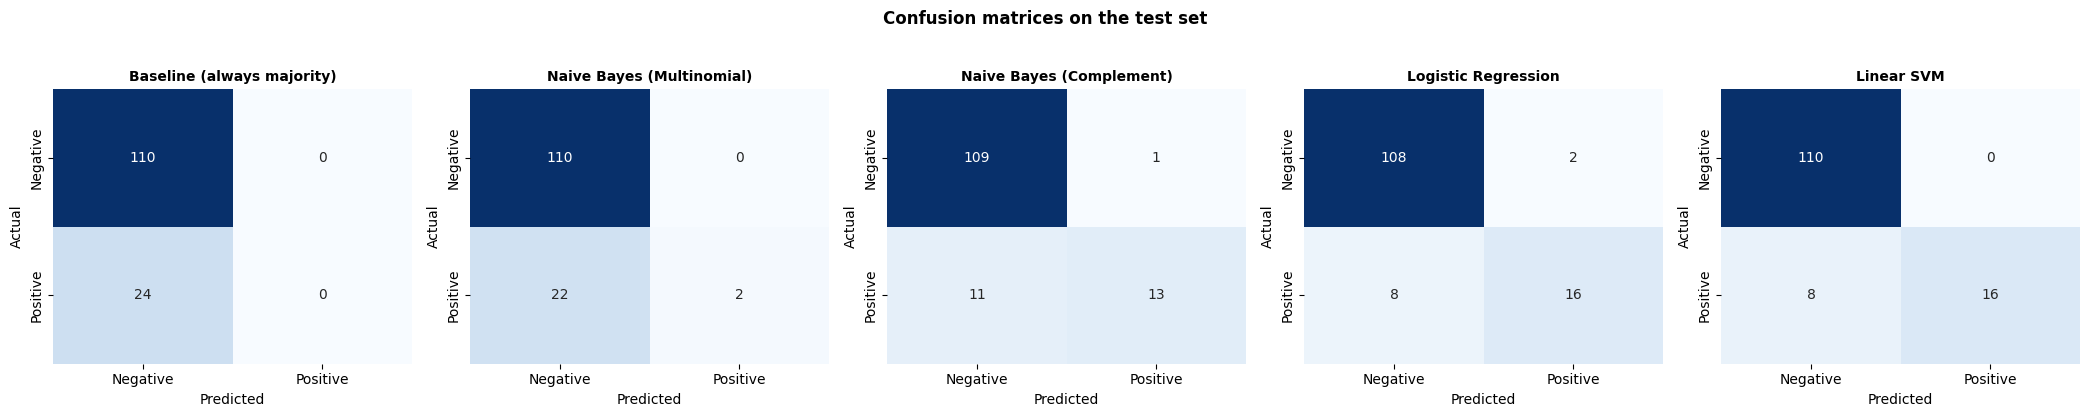

In [22]:
fig, axes = plt.subplots(1, 5, figsize=(21, 4))
for a, (name, p) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, p, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=a, xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])
    a.set_title(name, fontsize=10); a.set_xlabel("Predicted"); a.set_ylabel("Actual"); a.grid(False)
plt.suptitle("Confusion matrices on the test set", fontweight="bold", y=1.03); plt.tight_layout(); plt.show()

### 5.5 Compare the models – is accuracy enough on its own?

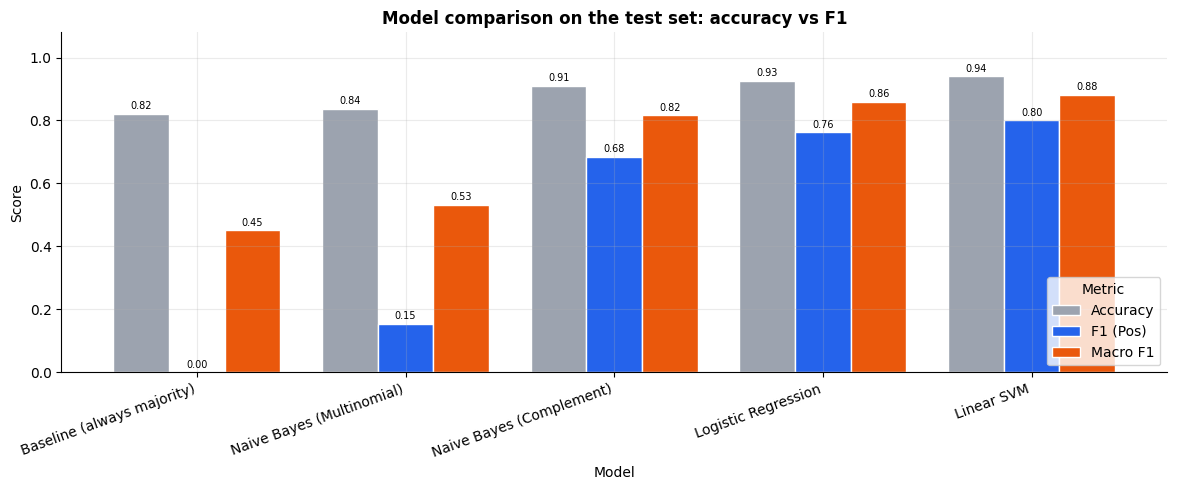

In [23]:
metrics_to_plot = ["Accuracy", "F1 (Pos)", "Macro F1"]
ax = results[metrics_to_plot].plot(kind="bar", figsize=(12, 5), color=[GREY_C, POS_C, NEG_C], width=.8, edgecolor="white")
ax.set_title("Model comparison on the test set: accuracy vs F1"); ax.set_ylabel("Score"); ax.set_xlabel("Model")
ax.set_ylim(0, 1.08); plt.xticks(rotation=20, ha="right"); ax.legend(title="Metric", loc="lower right")
for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=7, padding=2)
plt.tight_layout(); plt.show()

### 5.6 More reliable comparison: 5-fold cross-validation


In [24]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, m in models.items():
    s = cross_val_score(m, X_train, y_train, cv=cv, scoring="f1_macro")
    cv_rows.append((name, s.mean(), s.std()))
cv_df = pd.DataFrame(cv_rows, columns=["Model", "CV macro-F1 (mean)", "std"]).set_index("Model")
display(cv_df.round(3))

,CV macro-F1 (mean),std
Model,,
Baseline (always majority),0.450,0.001
Naive Bayes (Multinomial),0.509,0.036
Naive Bayes (Complement),0.826,0.041
Logistic Regression,0.847,0.050
Linear SVM,0.857,0.047


### 5.7 Bonus – tune the best models with cross-validation (GridSearchCV)


In [25]:
grids = {
    "Logistic Regression (tuned)": (make_pipe(LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE)),
        {"tfidf__ngram_range": [(1, 1), (1, 2)], "tfidf__min_df": [1, 2], "clf__C": [0.3, 1, 3, 10, 30]}),
    "Linear SVM (tuned)": (make_pipe(LinearSVC(class_weight="balanced", random_state=RANDOM_STATE)),
        {"tfidf__ngram_range": [(1, 1), (1, 2)], "tfidf__min_df": [1, 2], "clf__C": [0.05, 0.1, 0.3, 1, 3]}),
    "Naive Bayes (Complement, tuned)": (make_pipe(ComplementNB()),
        {"tfidf__ngram_range": [(1, 1), (1, 2)], "tfidf__min_df": [1, 2], "clf__alpha": [0.1, 0.3, 0.5, 1.0]}),
}
tuned, tuned_rows = {}, []
for name, (pipe, grid) in grids.items():
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="f1_macro", n_jobs=-1).fit(X_train, y_train)
    tuned[name] = gs.best_estimator_
    r, p = evaluate(name, gs.best_estimator_, X_test, y_test)
    r["CV macro-F1"] = gs.best_score_; r["best params"] = str({k.split("__")[-1]: v for k, v in gs.best_params_.items()})
    tuned_rows.append(r); preds[name] = p
tuned_df = pd.DataFrame(tuned_rows).set_index("Model")
display(tuned_df.round(3))

,Accuracy,Precision (Pos),Recall (Pos),F1 (Pos),Macro F1,Balanced Acc,CV macro-F1,best params
Model,,,,,,,,
Logistic Regression (tuned),0.925,0.818,0.750,0.783,0.869,0.857,0.871,"{'C': 0.3, 'min_df': 1, 'ngram_range': (1, 1)}"
Linear SVM (tuned),0.925,0.818,0.750,0.783,0.869,0.857,0.871,"{'C': 0.05, 'min_df': 1, 'ngram_range': (1, 1)}"
"Naive Bayes (Complement, tuned)",0.955,0.909,0.833,0.870,0.921,0.908,0.880,"{'alpha': 0.1, 'min_df': 2, 'ngram_range': (1, 2)}"


### 5.8 Bonus – compare with a ready-made tool (VADER)


In [26]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
vader = SentimentIntensityAnalyzer()
vader_pred = test_df.Review.apply(lambda t: int(vader.polarity_scores(t)["compound"] >= 0.05)).values
r, _ = evaluate("VADER (no training)", vader_pred, None, y_test)
preds["VADER (no training)"] = vader_pred

tuned_results = pd.DataFrame(tuned_rows).set_index("Model")[results.columns]
vader_results = pd.DataFrame([r]).set_index("Model")
final_table = pd.concat([results, tuned_results, vader_results]).round(3)
display(final_table.style.background_gradient(cmap="Blues", axis=0))

,Accuracy,Precision (Pos),Recall (Pos),F1 (Pos),Macro F1,Balanced Acc
Model,,,,,,
Baseline (always majority),0.821000,0.000000,0.000000,0.000000,0.451000,0.500000
Naive Bayes (Multinomial),0.836000,1.000000,0.083000,0.154000,0.531000,0.542000
Naive Bayes (Complement),0.910000,0.929000,0.542000,0.684000,0.816000,0.766000
Logistic Regression,0.925000,0.889000,0.667000,0.762000,0.859000,0.824000
Linear SVM,0.940000,1.000000,0.667000,0.800000,0.882000,0.833000
Logistic Regression (tuned),0.925000,0.818000,0.750000,0.783000,0.869000,0.857000
Linear SVM (tuned),0.925000,0.818000,0.750000,0.783000,0.869000,0.857000
"Naive Bayes (Complement, tuned)",0.955000,0.909000,0.833000,0.870000,0.921000,0.908000
VADER (no training),0.649000,0.328000,0.917000,0.484000,0.609000,0.754000


### 5.9 Choose, inspect and save the final model


Models within 0.01 of the best CV score: ['Logistic Regression (tuned)', 'Linear SVM (tuned)', 'Naive Bayes (Complement, tuned)']
Selected model: Logistic Regression (tuned) | CV macro-F1 = 0.871
Best params   : {'C': 0.3, 'min_df': 1, 'ngram_range': (1, 1)}

FINAL TEST RESULTS
              precision    recall  f1-score   support

    Negative       0.95      0.96      0.95       110
    Positive       0.82      0.75      0.78        24

    accuracy                           0.93       134
   macro avg       0.88      0.86      0.87       134
weighted avg       0.92      0.93      0.92       134



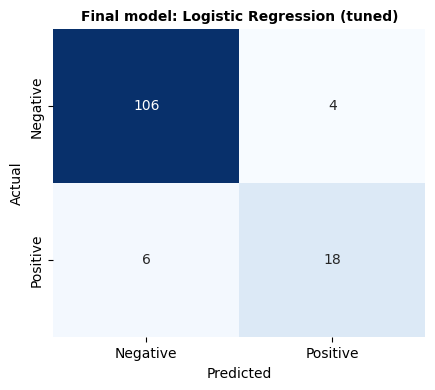

In [27]:
top_cv = tuned_df["CV macro-F1"].max()
near_tie = [k for k in tuned_df.index if tuned_df.loc[k, "CV macro-F1"] >= top_cv - 0.01]
print("Models within 0.01 of the best CV score:", near_tie)
best_name = next((k for k in near_tie if k.startswith("Logistic")), max(near_tie, key=lambda k: tuned_df.loc[k, "CV macro-F1"]))
final_model = tuned[best_name]
print("Selected model:", best_name, "| CV macro-F1 =", round(tuned_df.loc[best_name, "CV macro-F1"], 3))
print("Best params   :", tuned_df.loc[best_name, "best params"])

final_pred = final_model.predict(X_test)
print("\nFINAL TEST RESULTS"); print(classification_report(y_test, final_pred, target_names=["Negative", "Positive"], zero_division=0))
cm = confusion_matrix(y_test, final_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(4.8, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])
ax.set_title(f"Final model: {best_name}", fontsize=10); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.grid(False); plt.show()

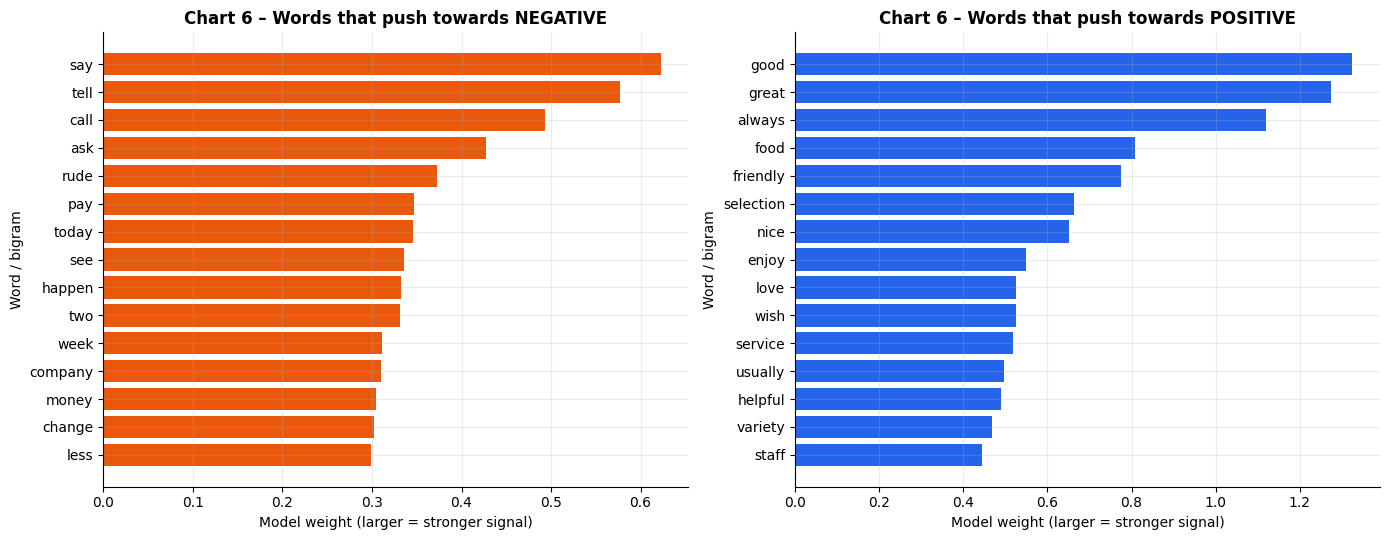

In [33]:
vec, clf = final_model.named_steps["tfidf"], final_model.named_steps["clf"]
if hasattr(clf, "coef_"):
    coefs = pd.Series(clf.coef_[0], index=vec.get_feature_names_out()).sort_values()
    top_neg, top_pos = coefs.head(15), coefs.tail(15)
    fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
    ax[0].barh(top_neg.index[::-1], -top_neg.values[::-1], color=NEG_C); ax[0].set_title("Chart 6 – Words that push towards NEGATIVE")
    ax[1].barh(top_pos.index, top_pos.values, color=POS_C); ax[1].set_title("Chart 6 – Words that push towards POSITIVE")
    for a in ax: a.set_xlabel("Model weight (larger = stronger signal)"); a.set_ylabel("Word / bigram")
    plt.tight_layout(); plt.show()

In [29]:
joblib.dump(final_model, "sentiment_model.joblib")
reloaded = joblib.load("sentiment_model.joblib")
assert (reloaded.predict(X_test) == final_model.predict(X_test)).all()
print("Saved + reloaded OK: sentiment_model.joblib (%.0f KB)" % (os.path.getsize("sentiment_model.joblib") / 1024))

final_metrics, _ = evaluate(best_name, final_pred, None, y_test)
info = {
    "model_name": best_name,
    "n_reviews": int(len(df)), "n_train": int(len(train_df)), "n_test": int(len(test_df)),
    "label_counts": df.sentiment.value_counts().to_dict(),
    "final_metrics": {k: float(v) for k, v in final_metrics.items() if k != "Model"},
    "confusion_matrix": cm.tolist(),
    "comparison": final_table.reset_index().rename(columns={"index": "Model"}).to_dict(orient="records"),
    "top_positive": {k: float(v) for k, v in (top_pos[::-1].items() if hasattr(clf, "coef_") else [])},
    "top_negative": {k: float(-v) for k, v in (top_neg.items() if hasattr(clf, "coef_") else [])},
}
json.dump(info, open("model_info.json", "w"), indent=2)
print("Saved model_info.json")

Saved + reloaded OK: sentiment_model.joblib (111 KB)
Saved model_info.json


---
# Part 6 – Predict on New Reviews


In [30]:
def predict_sentiment(review, model=reloaded, verbose=True):
    cleaned = clean_text(review)
    if not cleaned:
        if verbose: print("Could not find any usable words in this review.")
        return None
    clf = model.named_steps["clf"]
    if hasattr(clf, "predict_proba"):
        p_pos = float(model.predict_proba([cleaned])[0][1])
    else:
        p_pos = float(1 / (1 + np.exp(-2 * model.decision_function([cleaned])[0])))
    label = "Positive" if p_pos >= 0.5 else "Negative"
    if verbose:
        conf = p_pos if label == "Positive" else 1 - p_pos
        print(f"{label:<9} ({conf:.0%})  <-  {review}")
    return label

tests = [
    "The barista was friendly and my latte was perfect. I love this place!",
    "Terrible service. The coffee was cold and the staff was rude.",
    "The coffee was not good and the service was not great either.",
    "I would never go back, they got my order wrong again and nobody cared.",
    "Always fast, always smiling, best morning coffee in town.",
    "My drink was not hot and the cashier did not even say sorry.",
    "Not bad at all, the drink was really good!",
]
for t in tests:
    predict_sentiment(t)

Positive  (59%)  <-  The barista was friendly and my latte was perfect. I love this place!
Negative  (53%)  <-  Terrible service. The coffee was cold and the staff was rude.
Negative  (51%)  <-  The coffee was not good and the service was not great either.
Negative  (62%)  <-  I would never go back, they got my order wrong again and nobody cared.
Positive  (72%)  <-  Always fast, always smiling, best morning coffee in town.
Negative  (58%)  <-  My drink was not hot and the cashier did not even say sorry.
Positive  (73%)  <-  Not bad at all, the drink was really good!


---
# Part 7 – Conclusion

1. **What was messy:** 145 ratings were the text "N/A" (hidden as NaN by pandas), 37 rows said "No Review Text", `Date` was text with a "Reviewed" prefix and the unparsable "Sept.", `location` held two fields, `Image_Links` was a list stored as a string, plus masked `**` words, curly quotes, odd names, and a strong class imbalance (82% negative).
2. **What I did:** dropped rows with no rating or no text (850 → 703), converted the types (real datetimes, integer ratings, city/region split, image counts), then cleaned the text (lowercase, no links/symbols, contractions expanded, stop-words removed but **negations kept and fused to the next word**, lemmatised). Labels: 1–2★ = Negative, 4–5★ = Positive, 3★ dropped → **670 reviews (548 / 122)**.
3. **Which model worked best:** **Logistic Regression + TF-IDF** (tuned with 5-fold CV): 92.5% accuracy, Positive precision 0.82 / recall 0.75 / F1 0.78, macro-F1 0.87 on the held-out test set. It was chosen over SVM and Complement NB, which were statistically tied, because it gives probabilities and interpretable word weights. All trained models clearly beat VADER (64.9% accuracy) and the majority baseline (82% accuracy but 0 positives found).
4. **Limits:** only 670 labelled reviews (122 positive, 24 in the test set), so scores are noisy (±5 points); the data covers one brand and is complaint-heavy, so the model may not transfer to other products; a bag-of-words model cannot understand sarcasm or long-range context; the 3-star class is not modelled; 2017 is over-represented with positives; and rows without a rating were discarded rather than labelled.
5. **Next steps:** collect more positive reviews or use a pretrained transformer (e.g. DistilBERT) fine-tuned on this data, add a Neutral class, and monitor the app's predictions on new reviews.

In [31]:
%%writefile app.py
import json
import io
import numpy as np
import pandas as pd
import altair as alt
import joblib
import streamlit as st

from text_utils import clean_text

st.set_page_config(page_title="Review Sentiment Analyzer", page_icon="☕", layout="wide")

# ---------------------------------------------------------------- styling
st.markdown(
    """
<style>
@import url('https://fonts.googleapis.com/css2?family=Inter:wght@400;500;600;700;800&display=swap');
html, body, [class*="css"] { font-family: 'Inter', sans-serif; }
.block-container { padding-top: 1.6rem; max-width: 1150px; }
.hero {
    background: linear-gradient(135deg, #0b3d2e 0%, #14705a 55%, #1f9d7a 100%);
    border-radius: 20px; padding: 34px 38px; color: #fff; margin-bottom: 22px;
    box-shadow: 0 10px 30px rgba(11,61,46,.25);
}
.hero h1 { margin: 0 0 6px 0; font-size: 2.1rem; font-weight: 800; letter-spacing: -.02em; }
.hero p { margin: 0; opacity: .88; font-size: 1.02rem; }
.pill { display:inline-block; background:rgba(255,255,255,.16); border-radius:999px; padding:4px 12px;
        font-size:.78rem; margin:14px 8px 0 0; font-weight:500; }
.result { border-radius: 18px; padding: 26px 28px; border: 1px solid; margin-top: 6px; }
.result.pos { background:#eff6ff; border-color:#bfdbfe; }
.result.neg { background:#fff7ed; border-color:#fed7aa; }
.result .big { font-size: 2rem; font-weight: 800; margin: 0; letter-spacing:-.02em; }
.result.pos .big { color:#1d4ed8; } .result.neg .big { color:#c2410c; }
.result .sub { color:#475569; margin: 2px 0 14px 0; font-size:.95rem; }
.bar { height: 12px; border-radius: 999px; background:#e2e8f0; overflow:hidden; }
.bar > div { height: 100%; border-radius: 999px; }
.chip { display:inline-block; padding:5px 12px; border-radius:999px; margin:4px 6px 0 0; font-size:.86rem; font-weight:600; }
.chip.p { background:#dbeafe; color:#1e40af; } .chip.n { background:#ffedd5; color:#9a3412; }
.card { background: var(--secondary-background-color); border-radius:16px; padding:18px 20px; }
.small { color:#64748b; font-size:.85rem; }
div.stButton > button { border-radius: 12px; font-weight: 600; }
</style>
""",
    unsafe_allow_html=True,
)


# ---------------------------------------------------------------- model
@st.cache_resource
def load_assets():
    model = joblib.load("sentiment_model.joblib")
    with open("model_info.json") as f:
        info = json.load(f)
    return model, info


model, info = load_assets()
POS_C, NEG_C = "#2563eb", "#ea580c"


def score_positive(texts):
    """Return P(positive) for a list of already-cleaned texts."""
    clf = model.named_steps["clf"]
    if hasattr(clf, "predict_proba"):
        return model.predict_proba(texts)[:, 1]
    return 1 / (1 + np.exp(-2 * model.decision_function(texts)))


def explain(cleaned, top_k=8):
    """Words that pushed the decision (linear models): weight x tf-idf value."""
    vec, clf = model.named_steps["tfidf"], model.named_steps["clf"]
    if not hasattr(clf, "coef_"):
        return []
    X = vec.transform([cleaned])
    names = vec.get_feature_names_out()
    coef = clf.coef_[0]
    contrib = [(names[i], float(X[0, i] * coef[i])) for i in X.nonzero()[1]]
    return sorted(contrib, key=lambda t: -abs(t[1]))[:top_k]


# ---------------------------------------------------------------- header
fm = info["final_metrics"]
st.markdown(
    f"""
<div class="hero">
  <h1>☕ Review Sentiment Analyzer</h1>
  <p>Paste a customer review and the model tells you whether it is <b>Positive</b> or <b>Negative</b> — and which words decided it.</p>
  <span class="pill">Model: {info['model_name']}</span>
  <span class="pill">Trained on {info['n_train']} Starbucks reviews</span>
  <span class="pill">Test accuracy {fm['Accuracy']:.0%}</span>
  <span class="pill">Macro-F1 {fm['Macro F1']:.2f}</span>
</div>
""",
    unsafe_allow_html=True,
)

EXAMPLES = {
    "— pick an example —": "",
    "😊 Happy customer": "The barista was friendly and my latte was perfect. I love this place and will definitely come back!",
    "😡 Angry customer": "Terrible service. The coffee was cold, the order was wrong and the staff was rude to me.",
    "🔁 Negation: not good": "The coffee was not good and the service was not great either.",
    "🤔 Tricky: not bad": "Not bad at all, the drink was really good!",
    "📦 Wrong order": "I would never go back, they got my order wrong again and nobody cared.",
}

tab1, tab2, tab3 = st.tabs(["🔍 Analyze a review", "📂 Batch (CSV)", "📊 Model insights"])

# ---------------------------------------------------------------- tab 1
with tab1:
    left, right = st.columns([1.15, 1], gap="large")
    with left:
        def _load_example():
            ex = EXAMPLES[st.session_state["example_choice"]]
            if ex:
                st.session_state["review_text"] = ex

        st.selectbox("Try an example", list(EXAMPLES), key="example_choice", on_change=_load_example)
        text = st.text_area("Your review", key="review_text", height=190,
                            placeholder="Type or paste a review here…")
        go = st.button("Analyze sentiment", type="primary", width="stretch")
        st.caption("Tip: negations are understood — “not good” and “good” give opposite answers.")

    with right:
        if go or text.strip():
            cleaned = clean_text(text)
            if not text.strip():
                st.info("Write a review on the left to get started.")
            elif not cleaned:
                st.warning("I could not find any meaningful words in that text. Try a longer review.")
            else:
                p_pos = float(score_positive([cleaned])[0])
                is_pos = p_pos >= 0.5
                conf = p_pos if is_pos else 1 - p_pos
                cls, emoji, label = ("pos", "😊", "Positive") if is_pos else ("neg", "😞", "Negative")
                color = POS_C if is_pos else NEG_C
                st.markdown(
                    f"""
<div class="result {cls}">
  <p class="big">{emoji} {label}</p>
  <p class="sub">Model confidence: <b>{conf:.0%}</b></p>
  <div class="bar"><div style="width:{conf*100:.0f}%; background:{color}"></div></div>
  <p class="small" style="margin-top:10px">P(positive) = {p_pos:.0%} &nbsp;·&nbsp; P(negative) = {1-p_pos:.0%}</p>
</div>
""",
                    unsafe_allow_html=True,
                )
                words = explain(cleaned)
                if words:
                    st.markdown("**Why this prediction?**")
                    chips = "".join(
                        f'<span class="chip {"p" if w >= 0 else "n"}">{"＋" if w >= 0 else "－"} {t}</span>'
                        for t, w in words
                    )
                    st.markdown(chips, unsafe_allow_html=True)
                    st.caption("Blue words pushed towards Positive, orange towards Negative (strongest first).")
                with st.expander("See the cleaned text the model actually reads"):
                    st.code(cleaned, language=None)
        else:
            st.markdown(
                '<div class="card"><b>Result appears here</b><br><span class="small">Pick an example or write your own review, then press <i>Analyze sentiment</i>.</span></div>',
                unsafe_allow_html=True,
            )

# ---------------------------------------------------------------- tab 2
with tab2:
    st.markdown("Upload a CSV with a column of reviews to score them all at once.")
    up = st.file_uploader("CSV file", type=["csv"])
    if up is not None:
        data = pd.read_csv(up)
        guess = [c for c in data.columns if c.lower() in ("review", "text", "comment", "content")]
        col = st.selectbox("Which column contains the review text?", data.columns,
                           index=list(data.columns).index(guess[0]) if guess else 0)
        if st.button("Score all reviews", type="primary"):
            texts = data[col].astype(str)
            cleaned = texts.apply(clean_text)
            ok = cleaned.str.strip() != ""
            p = np.full(len(data), np.nan)
            if ok.any():
                p[ok.values] = score_positive(cleaned[ok].tolist())
            out = data.copy()
            out["sentiment"] = np.where(np.isnan(p), "Unknown", np.where(p >= 0.5, "Positive", "Negative"))
            out["confidence"] = np.where(np.isnan(p), np.nan, np.maximum(p, 1 - p)).round(3)
            c1, c2, c3 = st.columns(3)
            c1.metric("Reviews scored", int(ok.sum()))
            c2.metric("Positive", int((out.sentiment == "Positive").sum()))
            c3.metric("Negative", int((out.sentiment == "Negative").sum()))
            dist = out.sentiment.value_counts().rename_axis("sentiment").reset_index(name="count")
            st.altair_chart(
                alt.Chart(dist).mark_bar(cornerRadiusTopLeft=6, cornerRadiusTopRight=6).encode(
                    x=alt.X("sentiment:N", title="Sentiment", sort=["Negative", "Positive", "Unknown"]),
                    y=alt.Y("count:Q", title="Number of reviews"),
                    color=alt.Color("sentiment:N", legend=None,
                                    scale=alt.Scale(domain=["Negative", "Positive", "Unknown"], range=[NEG_C, POS_C, "#9ca3af"])),
                    tooltip=["sentiment", "count"],
                ).properties(height=260, title="Predicted sentiment"),
                width="stretch",
            )
            st.dataframe(out, width="stretch", height=320)
            st.download_button("⬇️ Download results (CSV)", out.to_csv(index=False).encode("utf-8"),
                               "sentiment_results.csv", "text/csv")

# ---------------------------------------------------------------- tab 3
with tab3:
    m1, m2, m3, m4, m5 = st.columns(5)
    m1.metric("Accuracy", f"{fm['Accuracy']:.1%}")
    m2.metric("Precision (Positive)", f"{fm['Precision (Pos)']:.2f}")
    m3.metric("Recall (Positive)", f"{fm['Recall (Pos)']:.2f}")
    m4.metric("F1 (Positive)", f"{fm['F1 (Pos)']:.2f}")
    m5.metric("Macro F1", f"{fm['Macro F1']:.2f}")
    st.caption(
        f"Test set: {info['n_test']} reviews the model never saw. Data: {info['label_counts'].get('Negative', 0)} negative vs "
        f"{info['label_counts'].get('Positive', 0)} positive — imbalanced, so accuracy alone is not enough; look at F1 and recall."
    )

    c1, c2 = st.columns(2, gap="large")
    with c1:
        cm = np.array(info["confusion_matrix"])
        cmdf = pd.DataFrame(
            [(a, p, int(cm[i, j])) for i, a in enumerate(["Negative", "Positive"]) for j, p in enumerate(["Negative", "Positive"])],
            columns=["Actual", "Predicted", "Reviews"],
        )
        base = alt.Chart(cmdf).encode(x=alt.X("Predicted:N", sort=["Negative", "Positive"]), y=alt.Y("Actual:N", sort=["Negative", "Positive"]))
        heat = base.mark_rect(cornerRadius=6).encode(color=alt.Color("Reviews:Q", scale=alt.Scale(scheme="blues"), legend=None))
        txt = base.mark_text(fontSize=22, fontWeight="bold").encode(text="Reviews:Q",
                                                                   color=alt.condition(alt.datum.Reviews > cm.max() / 2, alt.value("white"), alt.value("#0f172a")))
        st.altair_chart((heat + txt).properties(height=280, title="Confusion matrix (test set)"), width="stretch")
    with c2:
        comp = pd.DataFrame(info["comparison"])
        comp = comp[["Model", "Accuracy", "Macro F1"]].melt("Model", var_name="Metric", value_name="Score")
        st.altair_chart(
            alt.Chart(comp).mark_bar(cornerRadiusTopLeft=4, cornerRadiusTopRight=4).encode(
                x=alt.X("Score:Q", scale=alt.Scale(domain=[0, 1])),
                y=alt.Y("Model:N", sort="-x", title=None),
                yOffset="Metric:N",
                color=alt.Color("Metric:N", scale=alt.Scale(range=["#9ca3af", POS_C])),
                tooltip=["Model", "Metric", alt.Tooltip("Score:Q", format=".3f")],
            ).properties(height=280, title="All models: accuracy vs macro-F1"),
            width="stretch",
        )

    if info.get("top_positive"):
        w1, w2 = st.columns(2, gap="large")
        for col, key, color, title in [(w1, "top_negative", NEG_C, "Words that signal NEGATIVE"), (w2, "top_positive", POS_C, "Words that signal POSITIVE")]:
            d = pd.DataFrame({"word": list(info[key].keys()), "weight": list(info[key].values())}).head(12)
            col.altair_chart(
                alt.Chart(d).mark_bar(color=color, cornerRadiusTopRight=4, cornerRadiusBottomRight=4).encode(
                    x=alt.X("weight:Q", title="Model weight"), y=alt.Y("word:N", sort="-x", title=None),
                    tooltip=["word", alt.Tooltip("weight:Q", format=".2f")],
                ).properties(height=300, title=title),
                width="stretch",
            )

    st.markdown("##### Known limits")
    st.markdown(
        "- Trained on **a few hundred Starbucks reviews** — it may be less accurate on other products or on sarcasm.\n"
        "- Only two classes: 3-star (mixed) reviews were excluded from training.\n"
        "- The data is imbalanced (mostly negative), so the model is more reliable on negative reviews."
    )

Writing app.py


In [32]:
req = "streamlit>=1.50\nscikit-learn\npandas\nnumpy\nsimplemma\njoblib\naltair\n"
open("requirements.txt", "w").write(req)
print(req)
for f in ["app.py", "text_utils.py", "sentiment_model.joblib", "model_info.json", "cleaned_reviews.csv", "requirements.txt"]:
    print(f"{f:28} {'OK' if os.path.exists(f) else 'MISSING'}")

streamlit>=1.50
scikit-learn
pandas
numpy
simplemma
joblib
altair

app.py                       OK
text_utils.py                OK
sentiment_model.joblib       OK
model_info.json              OK
cleaned_reviews.csv          OK
requirements.txt             OK


In [36]:
readme_content = """# ☕ Starbucks Review Sentiment Analyzer

A production-ready machine learning and Streamlit application that analyzes and visualizes customer sentiments from Starbucks reviews. It uses a tuned **Logistic Regression model with TF-IDF vectorization** to classify reviews as Positive or Negative, providing granular word-level weight explanations.

## 🚀 Quick Start (Local Run)

To run the Streamlit web application locally, follow these steps:

### 1. Clone or Download this Project
Ensure you have the following files in the same directory:
- `app.py` (The main Streamlit interface)
- `text_utils.py` (Custom text preprocessing library preserving fused negations)
- `sentiment_model.joblib` (The serialized trained model pipeline)
- `model_info.json` (Model metadata, metrics, and word importance datasets)
- `requirements.txt` (List of dependencies)

### 2. Install Dependencies
Create a virtual environment (optional but recommended) and install the required libraries:
```bash
pip install -r requirements.txt
```

### 3. Run the Streamlit Server
Execute the following command in your terminal:
```bash
streamlit run app.py
```
The application will automatically open in your default browser at `http://localhost:8501`.

---

## 🌐 Deploy to Get a Public URL (Streamlit Community Cloud)

If you want a **free public URL** to share your Sentiment Analyzer web app with others, deployment is straightforward:

1. **Push your code to GitHub**:
   Create a GitHub repository containing all 5 essential assets listed in the local run section.
2. **Sign in to Streamlit**:
   Go to [Streamlit Community Cloud](https://share.streamlit.io/) and log in using your GitHub account.
3. **Deploy the App**:
   - Click **"New app"**.
   - Choose your repository, branch (usually `main` or `master`), and set the main file path to `app.py`.
   - Click **"Deploy!"**.
4. **Your Live URL**:
   Streamlit will build the container and provide you with a permanent public URL (e.g., `https://<your-app-name>.streamlit.app`).
"""

with open("README.md", "w") as f:
    f.write(readme_content)

try:
    from google.colab import files
    print("Triggering README.md download...")
    files.download("README.md")
except Exception as e:
    print("README.md created successfully. If not on Colab, you can find the file locally in your directory.")


Triggering README.md download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>